# Classifiers using raw patches

In [9]:
import matplotlib.pyplot as plt
import numpy as np

from common.config import (
    MAT_PATH,
    FIGS_DIR,
    TARGET_CLASS_NAMES,
    VALIDATION_FRACTION,
    TEST_FRACTION,
    RANDOM_STATE,
)
from common.utils import NYUDepthV2, make_data_splits, build_patches_dataset, binary_target_mask, extract_patch, evaluate

from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.neural_network import MLPClassifier

N_PIXELS = 100
PATCH_SIZE = 15

In [2]:
nyu = NYUDepthV2(MAT_PATH)
target_ids = [nyu.class_names.index(target) + 1 for target in TARGET_CLASS_NAMES]

In [3]:
# Create train/validation/test image indices
train_indices, val_indices, test_indices = make_data_splits(
    nyu_dataset=nyu,
    validation_fraction=VALIDATION_FRACTION,
    test_fraction=TEST_FRACTION,
    random_state=RANDOM_STATE,
)
print(f"Train images: {len(train_indices)}")
print(f"Validation images: {len(val_indices)}")
print(f"Test images: {len(test_indices)}")

Train images: 1028
Validation images: 206
Test images: 215


In [4]:
X_train, y_train, pos_train = build_patches_dataset(nyu, train_indices, target_ids,PATCH_SIZE, N_PIXELS, RANDOM_STATE)
X_test, y_test, pos_test = build_patches_dataset(nyu, test_indices, target_ids,PATCH_SIZE, N_PIXELS, RANDOM_STATE)
X_val, y_val, pos_val = build_patches_dataset(nyu, val_indices, target_ids, PATCH_SIZE, N_PIXELS, RANDOM_STATE)

In [5]:
# flatten: (N, 15, 15, 3) -> (N, 675)
X_train = X_train.reshape(len(X_train), -1)
X_val = X_val.reshape(len(X_val), -1)
X_test = X_test.reshape(len(X_test), -1)

print(X_train.shape, X_val.shape, X_test.shape)

(102800, 675) (20600, 675) (21500, 675)


## Logistic

/opt/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


AUC:      0.649
AP:       0.178
Accuracy: 0.617  (baseline 'always not floor': 0.885)
IoU:      0.152
              precision    recall  f1-score   support

   not floor       0.92      0.62      0.74     19035
       floor       0.17      0.60      0.26      2465

    accuracy                           0.62     21500
   macro avg       0.55      0.61      0.50     21500
weighted avg       0.84      0.62      0.69     21500



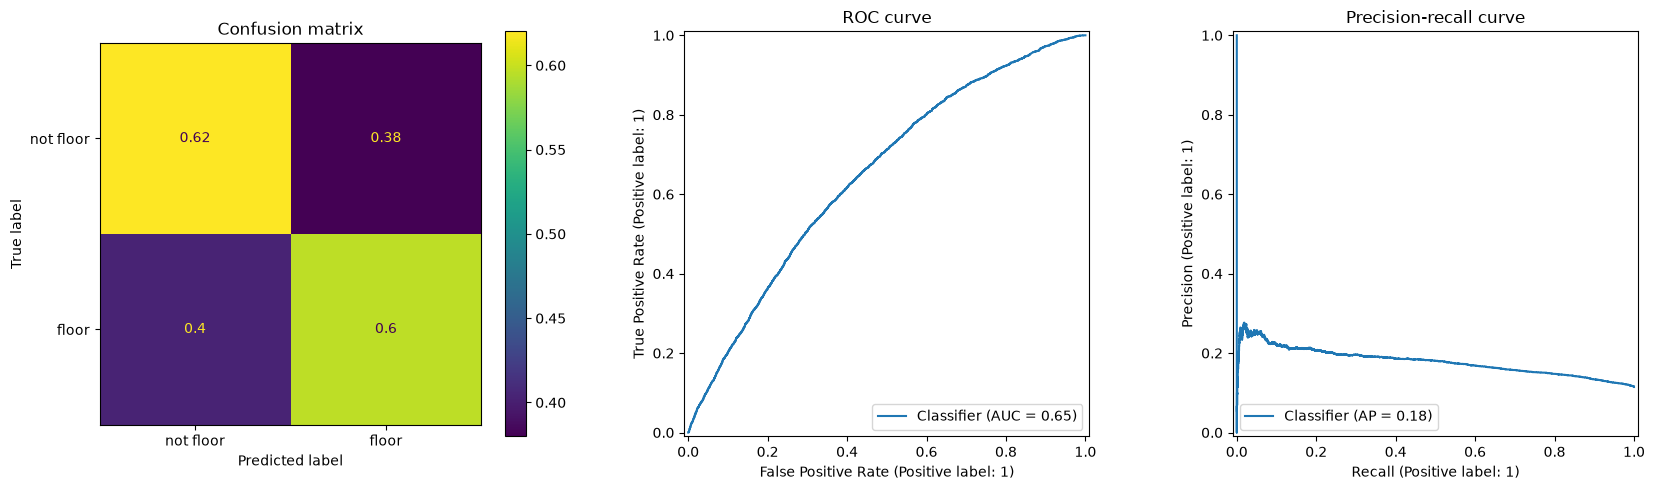

In [6]:
clf_lr = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
clf_lr.fit(X_train, y_train)

proba_lr = clf_lr.predict_proba(X_test)[:, 1]
evaluate(y_test, proba_lr)

## Random Forest

AUC:      0.728
AP:       0.263
Accuracy: 0.827  (baseline 'always not floor': 0.885)
IoU:      0.183
              precision    recall  f1-score   support

   not floor       0.91      0.89      0.90     19035
       floor       0.28      0.34      0.31      2465

    accuracy                           0.83     21500
   macro avg       0.60      0.61      0.61     21500
weighted avg       0.84      0.83      0.83     21500



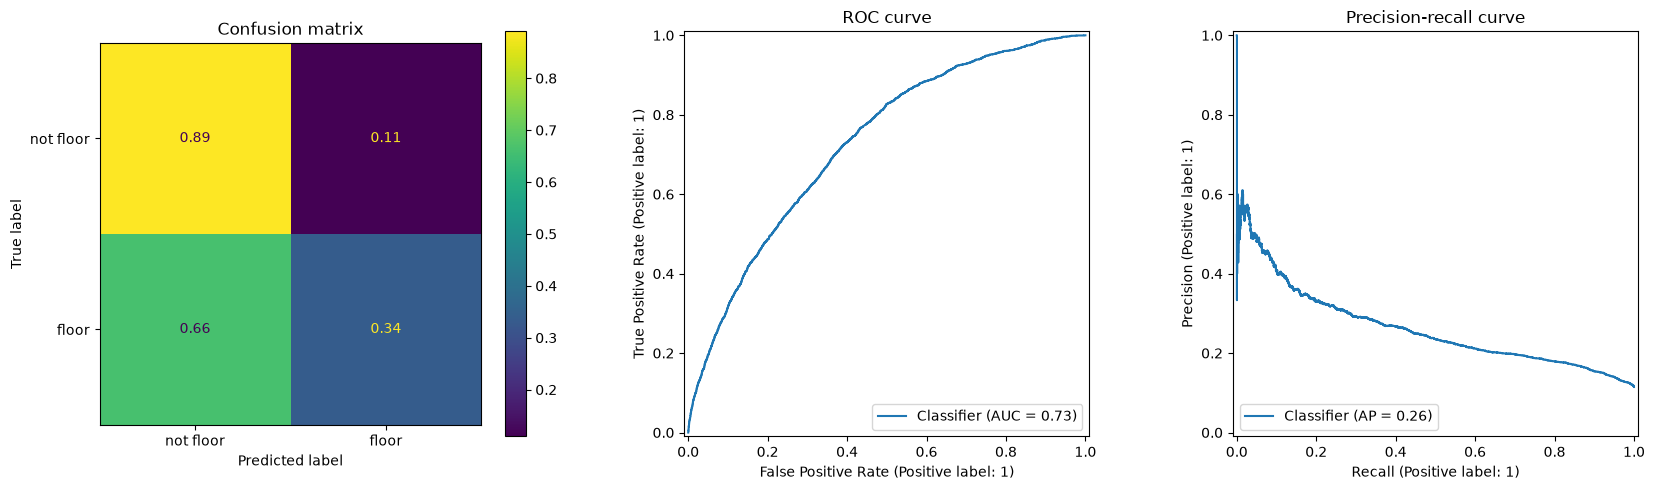

In [7]:
clf_rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=20,
                                class_weight="balanced_subsample",
                                n_jobs=-1, random_state=RANDOM_STATE)
clf_rf.fit(X_train, y_train)

proba_rf = clf_rf.predict_proba(X_test)[:, 1]
evaluate(y_test, proba_rf)

## SVM

AUC:      0.646
AP:       0.169
Accuracy: 0.548  (baseline 'always not floor': 0.885)
IoU:      0.147
              precision    recall  f1-score   support

   not floor       0.93      0.53      0.68     19035
       floor       0.16      0.68      0.26      2465

    accuracy                           0.55     21500
   macro avg       0.54      0.60      0.47     21500
weighted avg       0.84      0.55      0.63     21500



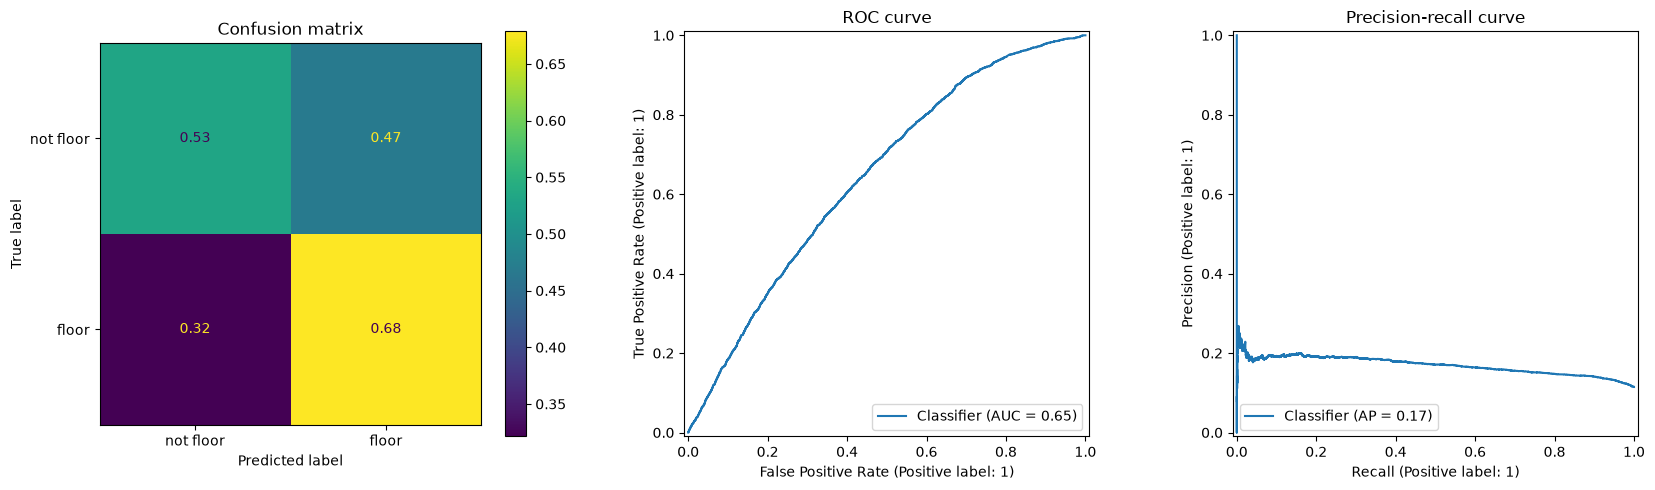

In [8]:
rng = np.random.default_rng(RANDOM_STATE)
subset = rng.choice(len(X_train), size=10000, replace=False)

clf_svm = make_pipeline(StandardScaler(), PCA(50, random_state=RANDOM_STATE), SVC(class_weight="balanced"))
clf_svm.fit(X_train[subset], y_train[subset])

score_svm = clf_svm.decision_function(X_test)
evaluate(y_test, score_svm, threshold=0)

## MLP

AUC:      0.679
AP:       0.229
Accuracy: 0.615  (baseline 'always not floor': 0.885)
IoU:      0.160
              precision    recall  f1-score   support

   not floor       0.93      0.61      0.74     19035
       floor       0.18      0.64      0.28      2465

    accuracy                           0.61     21500
   macro avg       0.55      0.63      0.51     21500
weighted avg       0.84      0.61      0.68     21500



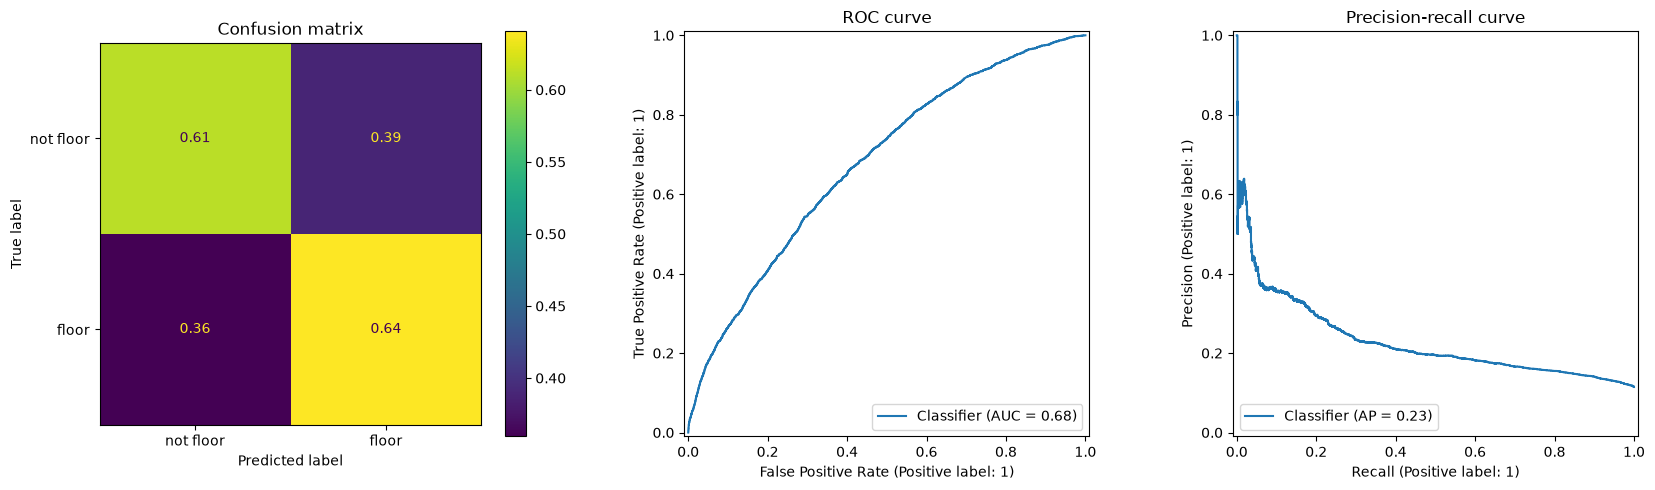

In [10]:
clf_mlp = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(256, 64),
                        batch_size=256, max_iter=30, early_stopping=True, random_state=RANDOM_STATE))
clf_mlp.fit(X_train, y_train,
            mlpclassifier__sample_weight=compute_sample_weight("balanced", y_train))

proba_mlp = clf_mlp.predict_proba(X_test)[:, 1]
evaluate(y_test, proba_mlp)

## Masks

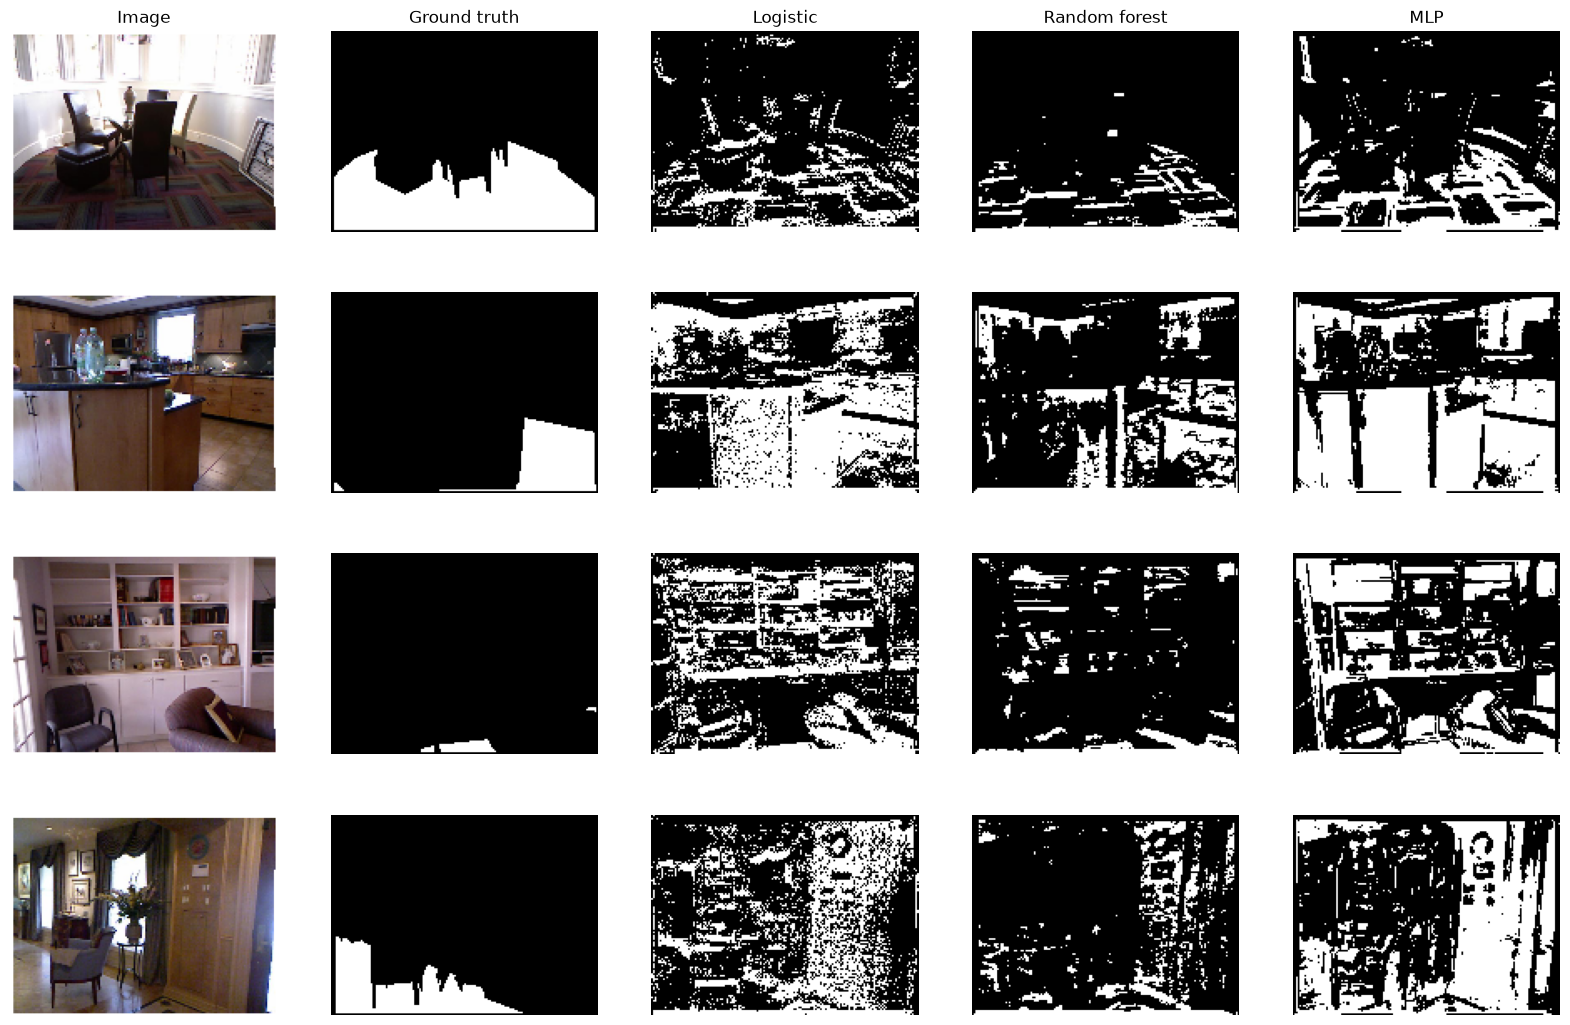

In [11]:
STRIDE = 4   # predict one pixel every 4 (faster)
p = PATCH_SIZE // 2

fig, axes = plt.subplots(4, 5, figsize=(20, 13))

for row, idx in enumerate(test_indices[:4]):
    image, labels = nyu.get_pair(idx)
    gt = binary_target_mask(labels, target_ids)

    # Build one flattened patch for each pixel on the grid
    padded = np.pad(image, ((p, p), (p, p), (0, 0)), mode="edge")
    rows = range(0, image.shape[0], STRIDE)
    cols = range(0, image.shape[1], STRIDE)
    X = np.array([extract_patch(padded, r + p, c + p, PATCH_SIZE) for r in rows for c in cols])
    X = (X.astype(np.float32) / 255.0).reshape(len(X), -1)

    probas = [
        clf_lr.predict_proba(X)[:, 1],
        clf_rf.predict_proba(X)[:, 1],
        clf_mlp.predict_proba(X)[:, 1]
    ]

    axes[row, 0].imshow(image[::STRIDE, ::STRIDE])
    axes[row, 1].imshow(gt[::STRIDE, ::STRIDE], cmap="gray")
    for k, proba in enumerate(probas):
        pred = proba.reshape(len(rows), len(cols)) >= 0.5
        axes[row, 2 + k].imshow(pred, cmap="gray", vmin=0, vmax=1)

for ax, title in zip(axes[0], ["Image", "Ground truth", "Logistic", "Random forest", "MLP"]):
    ax.set_title(title)

for ax in axes.ravel():
    ax.axis("off")

plt.show()